# [GALT] Vežba 1: GAIA catalogue & basic statistics

In [31]:
from astroquery.gaia import Gaia
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.coordinates import SkyCoord, Angle
from scipy.optimize import least_squares

In [2]:
# zvezde spektralnog tipa O (Teff >= 30,000 K)
# uzimamo samo 2000

o_query = """
SELECT TOP 3000
    g.source_id, 
    g.ra, 
    g.dec, 
    g.parallax, 
    g.parallax_over_error, 
    g.pmra, 
    g.pmdec, 
    g.phot_g_mean_mag, 
    g.bp_rp,
    a.teff_gspphot
FROM gaiadr3.gaia_source AS g
JOIN gaiadr3.astrophysical_parameters AS a ON g.source_id = a.source_id
WHERE a.teff_gspphot >= 30000
  AND g.parallax > 0
  AND g.parallax_over_error > 5
"""

job_o = Gaia.launch_job_async(o_query)
df_o = job_o.get_results().to_pandas()
df_o.to_csv("o_stars.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [3]:
# učitavam podatke za O: ra, dec i parallax
df_o = pd.read_csv("o_stars.csv")
o_data = df_o[["ra", "dec", "parallax"]]

In [4]:
# učitavamo celi katalog - Vizier ima svoj row limit
Vizier.ROW_LIMIT = -1

# globularna jata
globular_result = Vizier.get_catalog##s("VII/202")
df_globular = globular_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_globular_clean = df_globular[["ID", "RAJ2000", "DEJ2000"]]
df_globular_clean.to_csv("globular_clusters_harris.csv", index=False)

# otvorena jata
open_result = Vizier.get_catalogs("B/ocl")
df_open = open_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_open_clean = df_open[["RAJ2000", "DEJ2000", "Dist"]]
df_open_clean.to_csv("open_clusters_dias.csv", index=False)

### 1. Prikazati grafik DEC od RA, pri čemu razlicitim simbolima oznaciti otvorena zvezdana jata i O zvezde.

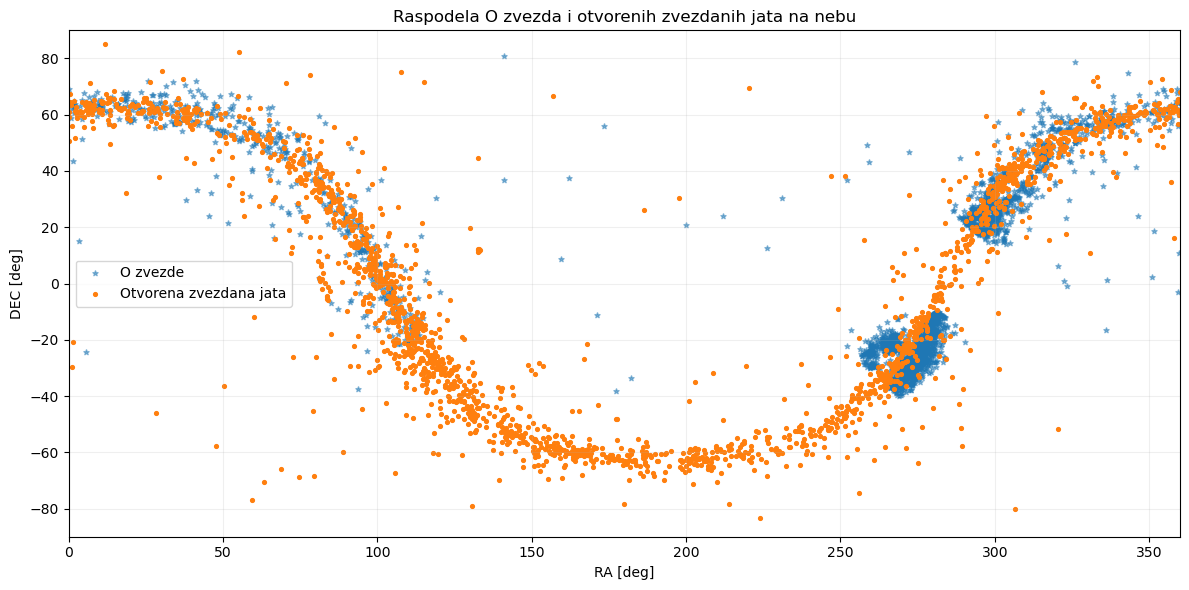

In [18]:
# Funkcija za pretvaranje RA iz formata HH MM SS u stepene
def ra_to_degrees(ra):
    h, m, s = map(float, ra.split())
    return 15 * (h + m / 60 + s / 3600)

# Funkcija za pretvaranje DEC iz formata +DD MM SS u stepene
def dec_to_degrees(dec):
    parts = dec.split()

    sign = -1 if parts[0].startswith("-") else 1

    d = abs(float(parts[0]))
    m = float(parts[1])
    s = float(parts[2])

    return sign * (d + m / 60 + s / 3600)


# Kopiramo podatke da ne menjamo originalni DataFrame
open_plot = df_open_clean.copy()

# Pretvaramo koordinate u decimalne stepene
open_plot["RA_deg"] = open_plot["RAJ2000"].apply(ra_to_degrees)
open_plot["DEC_deg"] = open_plot["DEJ2000"].apply(dec_to_degrees)

# Crtamo grafik
fig, ax = plt.subplots(figsize=(12, 6))

# O zvezde
ax.scatter(
    o_data["ra"],
    o_data["dec"],
    marker="*",
    s=15,
    alpha=0.5,
    label="O zvezde"
)

# Otvorena zvezdana jata
ax.scatter(
    open_plot["RA_deg"],
    open_plot["DEC_deg"],
    marker=".",
    s=30,
    label="Otvorena zvezdana jata"
)

ax.set_xlabel("RA [deg]")
ax.set_ylabel("DEC [deg]")
ax.set_title("Raspodela O zvezda i otvorenih zvezdanih jata na nebu")

ax.set_xlim(0, 360)
ax.set_ylim(-90, 90)

ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 2. Odrediti udaljenosti do O zvezda. (Hint: Obratiti pažnju u kojoj jedinici je data paralaksa.)


In [24]:
# Udaljenost u parsecima
df_o["distance_pc"] = 1000 / df_o["parallax"]

# Udaljenost u svetlosnim godinama
df_o["distance_ly"] = df_o["distance_pc"] * 3.26156

print("Statistika udaljenosti O zvezdi:")
print(df_o["distance_pc"].describe())

Statistika udaljenosti O zvezdi:
count     3000.000000
mean      5128.129389
std       2000.626351
min        143.938283
25%       3655.720564
50%       5208.409915
75%       6493.766942
max      16370.126908
Name: distance_pc, dtype: float64


### 3. Određivanje položaja severnog galaktičkog pola

Rezultati fitovanja:
alpha_w = 284.5577 deg
i = 62.0874 deg

Severni galaktički pol:
RA = 194.5577 deg
DEC = 27.9126 deg
RA = 12.9705 h


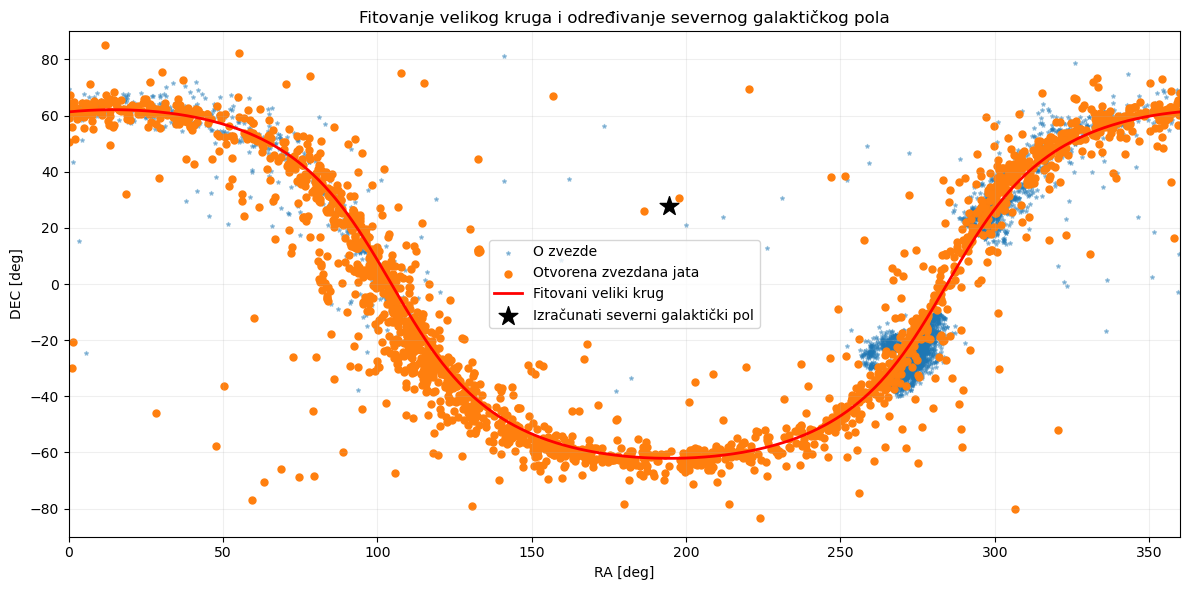

In [28]:
# 1. Spajanje koordinata O zvezda i otvorenih jata

ra_o = o_data["ra"].to_numpy(dtype=float)
dec_o = o_data["dec"].to_numpy(dtype=float)

ra_open = open_plot["RA_deg"].to_numpy(dtype=float)
dec_open = open_plot["DEC_deg"].to_numpy(dtype=float)

ra_all = np.concatenate([ra_o, ra_open])
dec_all = np.concatenate([dec_o, dec_open])

# Uklanjamo eventualne neispravne vrednosti
valid = (
    np.isfinite(ra_all) &
    np.isfinite(dec_all) &
    (dec_all >= -90) &
    (dec_all <= 90)
)

ra_all = ra_all[valid]
dec_all = dec_all[valid]

# Pretvaramo uglove iz stepeni u radijane
ra_rad = np.deg2rad(ra_all)
dec_rad = np.deg2rad(dec_all)


# 2. Jednačina velikog kruga

def model_dec(ra, alpha_w, inclination):
    return np.arctan(
        np.sin(ra - alpha_w) * np.tan(inclination)
    )


# 3. Funkcija reziduala

def residuals(params, ra, dec):
    alpha_w, inclination = params
    predicted_dec = model_dec(ra, alpha_w, inclination)
    return dec - predicted_dec


# Početne vrednosti za optimizaciju
initial_alpha_w = np.deg2rad(280)
initial_i = np.deg2rad(60)

# Fitovanje
fit = least_squares(
    residuals,
    x0=[initial_alpha_w, initial_i],
    args=(ra_rad, dec_rad),
    loss="soft_l1"
)

alpha_w_fit, i_fit = fit.x

# Rezultati u stepenima
alpha_w_deg = np.rad2deg(alpha_w_fit) % 360
i_deg = np.rad2deg(i_fit)

# Koordinate severnog galaktičkog pola
alpha_pole_deg = (alpha_w_deg - 90) % 360
dec_pole_deg = 90 - i_deg

# Pretvaranje rektascenzije u sate
alpha_pole_hours = alpha_pole_deg / 15

print("Rezultati fitovanja:")
print(f"alpha_w = {alpha_w_deg:.4f} deg")
print(f"i = {i_deg:.4f} deg")

print("\nSeverni galaktički pol:")
print(f"RA = {alpha_pole_deg:.4f} deg")
print(f"DEC = {dec_pole_deg:.4f} deg")
print(f"RA = {alpha_pole_hours:.4f} h")


# 4. Grafik: podaci i fitovani veliki krug

ra_curve_deg = np.linspace(0, 360, 1000)
ra_curve_rad = np.deg2rad(ra_curve_deg)

dec_curve_rad = model_dec(
    ra_curve_rad,
    alpha_w_fit,
    i_fit
)

dec_curve_deg = np.rad2deg(dec_curve_rad)

plt.figure(figsize=(12, 6))

plt.scatter(
    ra_o, dec_o,
    s=8, marker="*",
    alpha=0.4,
    label="O zvezde"
)

plt.scatter(
    ra_open, dec_open,
    s=25, marker="o",
    label="Otvorena zvezdana jata"
)

plt.plot(
    ra_curve_deg,
    dec_curve_deg,
    "r-",
    linewidth=2,
    label="Fitovani veliki krug"
)

plt.scatter(
    alpha_pole_deg,
    dec_pole_deg,
    marker="*",
    s=200,
    color="black",
    label="Izračunati severni galaktički pol",
    zorder=5
)

plt.xlabel("RA [deg]")
plt.ylabel("DEC [deg]")
plt.title("Fitovanje velikog kruga i određivanje severnog galaktičkog pola")
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

### 4. Izračunati galaktičke koordinate l i b za globularna jata. (Možete npr. koristiti funkciju SkyCoord.)

In [36]:
# Kopiramo katalog
df_gc = df_globular_clean.copy()

# Pretvaramo RA iz sati, minuta i sekundi u stepene
ra_deg = Angle(
    df_gc["RAJ2000"].astype(str),
    unit=u.hourangle
).degree

# Pretvaramo DEC iz stepeni, lučnih minuta i sekundi u stepene
dec_deg = Angle(
    df_gc["DEJ2000"].astype(str),
    unit=u.deg
).degree

# Formiramo nebeske koordinate
coords = SkyCoord(
    ra=ra_deg * u.deg,
    dec=dec_deg * u.deg,
    frame="icrs"
)

# Transformacija u galaktički koordinatni sistem
galactic = coords.galactic

# Dodajemo galaktičke koordinate u katalog
df_gc["l"] = galactic.l.deg
df_gc["b"] = galactic.b.deg

# Čuvanje rezultata
df_gc.to_csv("globular_clusters_galactic.csv", index=False)

# Osnovna statistika galaktičkih koordinata
print("Statistička analiza galaktičkih koordinata globularnih jata:\n")

print(df_gc[["l", "b"]].describe())

Statistička analiza galaktičkih koordinata globularnih jata:

                l           b
count  147.000000  147.000000
mean   165.986632    1.574986
std    152.626130   26.844705
min      0.069917  -89.382849
25%      9.853966  -11.042005
50%     87.103384   -0.160103
75%    334.328982   11.346911
max    359.584785   79.764981
